In [56]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt

In [57]:
#Constants

def golden_ratio(N):
    # 1 + 1/(1 + 1/(1 + ...))
    t = 1
    for i in range(N):
        t = 1 + 1 / t
    return t

def sqrt2(N):
    # 1 + 1/(2 + 1/(2 + ...))
    t = 2
    for i in range(N):
        t = 2 + 1 / t
    return 1 + 1 / t

def pi_cf(N):
    # 3 + 1^2/(6 + 3^2/(6 + 5^2/(6 + ...)))
    t = 6
    for n in range(N, 1, -1):
        t = 6 + (2*n - 1)**2 / t
    return 3 + 1 / t

def e_cf(N):
    # 2 + 1/(1 + 1/(2 + 2/(3 + 3/(4 + ...))))
    t = N
    for n in range(N, 1, -1):
        t = (n - 1) + (n - 1) / t
    return 2 + 1 / t

def ln2_cf(N):
    # ln(1+x) at x = 1: x/(1 + 1^2 x/(2 + 1^2 x/(3 + 2^2 x/(4 + ...))))
    t = N
    for n in range(N, 1, -1):
        t = (n - 1) + (n // 2)**2 / t
    return 1 / t

In [58]:
rows = [("golden ratio", golden_ratio, 50, (1 + np.sqrt(5)) / 2),
    ("sqrt(2)", sqrt2, 50, np.sqrt(2)),
    ("pi", pi_cf, 50, np.pi),
    ("e", e_cf, 50, np.e),
    ("ln 2", ln2_cf, 50, np.log(2)),]

print(f"{'constant':<14}{'N':>6}{'approx':>20}{'reference':>20}{'abs error':>13}{'rel error':>13}")
for name, func, N, ref in rows:
    approx = func(N)
    abs_err = abs(approx - ref)
    print(f"{name:<14}{N:>6}{approx:>20.15f}{ref:>20.15f}{abs_err:>13.2e}{abs_err/abs(ref):>13.2e}")

constant           N              approx           reference    abs error    rel error
golden ratio      50   1.618033988749895   1.618033988749895     0.00e+00     0.00e+00
sqrt(2)           50   1.414213562373095   1.414213562373095     0.00e+00     0.00e+00
pi                50   3.141590769849795   3.141592653589793     1.88e-06     6.00e-07
e                 50   2.718281828459046   2.718281828459045     4.44e-16     1.63e-16
ln 2              50   0.693147180559945   0.693147180559945     0.00e+00     0.00e+00


In [59]:
#Functions

def sqrt1px_cf(x, N):
    # 1 + x/(2 + x/(2 + ...))
    t = 2
    for i in range(N):
        t = 2 + x / t
    return 1 + x / t

def ln1px_cf(x, N):
    # x/(1 + x/(2 + x/(3 + 4x/(4 + 4x/(5 + 9x/(6 + ...))))))
    t = N
    for n in range(N, 1, -1):
        t = (n - 1) + (n // 2)**2 * x / t
    return x / t

def arctan_cf(x, N):
    # x/(1 + x^2/(3 + 4x^2/(5 + 9x^2/(7 + ...))))
    t = 2*N - 1
    for n in range(N, 1, -1):
        t = (2*n - 3) + (n - 1)**2 * x**2 / t
    return x / t

def tan_cf(x, N):
    # x/(1 - x^2/(3 - x^2/(5 - ...)))
    t = 2*N - 1
    for n in range(N, 1, -1):
        t = (2*n - 3) - x**2 / t
    return x / t

def tanh_cf(x, N):
    # x/(1 + x^2/(3 + x^2/(5 + ...)))
    t = 2*N - 1
    for n in range(N, 1, -1):
        t = (2*n - 3) + x**2 / t
    return x / t

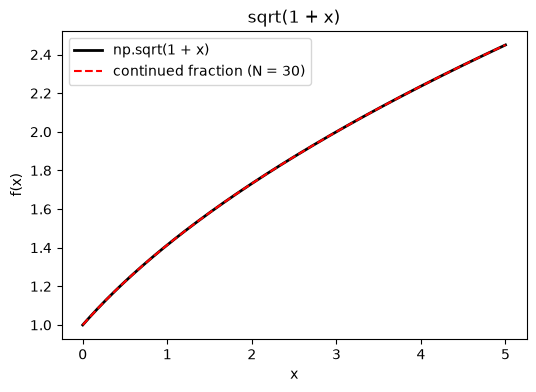

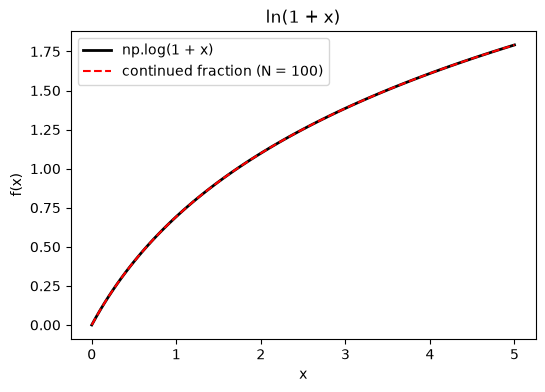

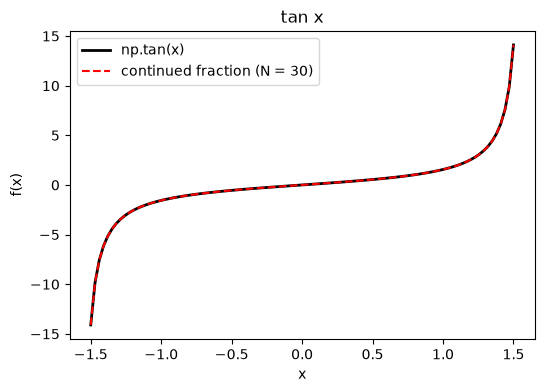

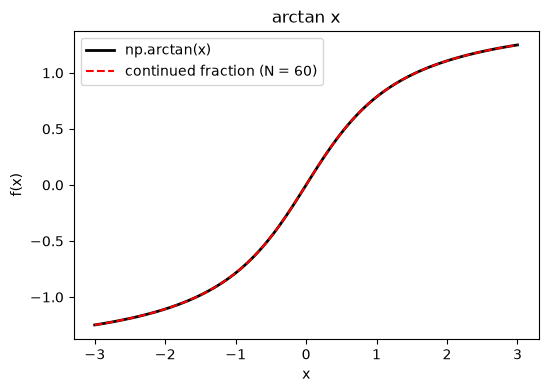

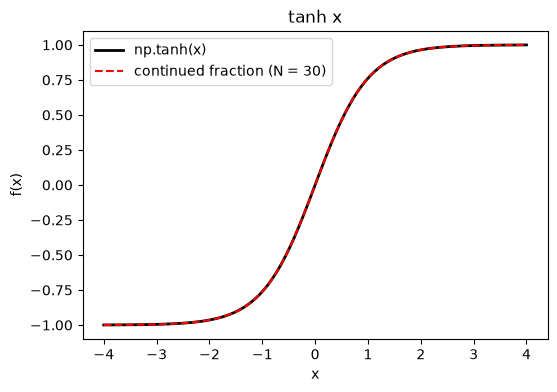

In [60]:
def np_sqrt1(x): return np.sqrt(1 + x)
def np_ln1(x):   return np.log(1 + x)

# sqrt(1 + x)
N = 30
x = np.linspace(0, 5, 200)

plt.figure(figsize=(6, 4))
plt.plot(x, np.sqrt(1 + x), "k", lw=2, label="np.sqrt(1 + x)")
plt.plot(x, sqrt1px_cf(x, N), "r--", label=f"continued fraction (N = {N})")
plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("sqrt(1 + x)")
plt.legend()
plt.show()

# ln(1 + x)
N = 100
x = np.linspace(0, 5, 101)

plt.figure(figsize=(6, 4))
plt.plot(x, np.log(1 + x), "k", lw=2, label="np.log(1 + x)")
plt.plot(x, ln1px_cf(x, N), "r--", label=f"continued fraction (N = {N})")
plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("ln(1 + x)")
plt.legend()
plt.show()

# tan x
N = 30
x = np.linspace(-1.5, 1.5, 101)

plt.figure(figsize=(6, 4))
plt.plot(x, np.tan(x), "k", lw=2, label="np.tan(x)")
plt.plot(x, tan_cf(x, N), "r--", label=f"continued fraction (N = {N})")
plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("tan x")
plt.legend()
plt.show()

# arctan x
N = 60
x = np.linspace(-3, 3, 101)

plt.figure(figsize=(6, 4))
plt.plot(x, np.arctan(x), "k", lw=2, label="np.arctan(x)")
plt.plot(x, arctan_cf(x, N), "r--", label=f"continued fraction (N = {N})")
plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("arctan x")
plt.legend()
plt.show()

# tanh x
N = 30
x = np.linspace(-4, 4, 101)

plt.figure(figsize=(6, 4))
plt.plot(x, np.tanh(x), "k", lw=2, label="np.tanh(x)")
plt.plot(x, tanh_cf(x, N), "r--", label=f"continued fraction (N = {N})")
plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("tanh x")
plt.legend()
plt.show()
